# 02 — Pulizia del dataset

Il notebook 01 ha trovato le testate parenti. Qui decidiamo **che cosa fare del testo copiato**, sempre
**senza guardare le etichette** (le usiamo solo nell'ultima sezione, per descrivere le versioni finali del dataset,
quando tutte le regole sono già state applicate). Quattro passi, in quest'ordine:

1. **una sola copia per articolo:** se lo stesso articolo (con ritocchi minimi) compare su più testate, se ne tiene una;
2. **niente copie tra gruppi diversi:** gli articoli che hanno ancora una copia in un altro gruppo vengono tolti;
3. **via i paragrafi condivisi:** i paragrafi che compaiono identici in più testate (didascalie, modelli, appelli, avvisi) non sono testo originale dell'articolo;
4. **via gli articoli troppo corti:** se dopo la pulizia restano 100 parole o meno, l'articolo si toglie (la stessa soglia usata nello scraping).

L'ordine conta: se togliessimo prima i paragrafi condivisi, un articolo ripreso per intero da due testate
sparirebbe da **entrambe**; togliendo prima le copie, ne resta una.

Alla fine prepariamo **tre versioni** del dataset pulito: senza un minimo di articoli per testata, con almeno 10
e con almeno 20. I **gruppi** del notebook 01 diventano l'unità con cui si dividono i fold (cartella `2-classificazione`).

In [1]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from datasketch import MinHash, MinHashLSH
from comune import carica_dataset, normalizza, DERIVED, PULITO, RESULTS, SEED, LIVELLI

df = carica_dataset().drop(columns=["label", "score"])   # niente etichette in questo notebook
gruppo = pd.read_csv(RESULTS + "01_gruppi_testate.csv", index_col="domain").gruppo
coppie = pd.read_csv(DERIVED + "01_coppie_quasi_uguali.csv.gz")
df["gruppo"] = df.domain.map(gruppo)
tolti = {}   # articolo -> motivo

print(len(df), "articoli,", df.domain.nunique(), "testate")

19476 articoli, 439 testate


## Passo 1 — Una sola copia per articolo

Due articoli sono **lo stesso articolo** se la somiglianza è almeno **0,9** (stessi pezzetti di 5 parole per il 90%):
è lo stesso testo con poche parole cambiate (es. un pezzo ripreso, o un articolo-modello in cui cambia solo il nome
della contea). Tra 0,5 e 0,9 ci sono invece articoli che condividono **parti** di testo ma hanno contenuto diverso:
quelli non si tolgono, le parti comuni spariranno al passo 3.

Le copie dello stesso articolo formano una **famiglia**; per ogni famiglia se ne tiene una, scelta a caso (seed 42).

Perché 0,9 e non più in basso: abbassando la soglia, articoli simili a catena (A simile a B, B simile a C, …)
si fondono in famiglie enormi che non sono più "lo stesso articolo".

In [2]:
def famiglie(soglia):
    G = nx.Graph()
    G.add_edges_from(coppie[coppie.jaccard >= soglia][["articolo_a", "articolo_b"]].itertuples(index=False))
    return sorted(nx.connected_components(G), key=len, reverse=True)

righe = []
for soglia in [0.7, 0.8, 0.9, 0.95]:
    f = famiglie(soglia)
    righe.append({"somiglianza min.": soglia, "famiglie": len(f), "articoli coinvolti": sum(map(len, f)),
                  "famiglia più grande": len(f[0]), "articoli tolti tenendo una copia": sum(map(len, f)) - len(f)})
pd.DataFrame(righe)

,somiglianza min.,famiglie,articoli coinvolti,famiglia più grande,articoli tolti tenendo una copia
0,0.70,736,4407,1680,3671
1,0.80,709,4070,1672,3361
2,0.90,733,2568,52,1835
3,0.95,649,1734,19,1085


In [3]:
rng = np.random.default_rng(SEED)
for famiglia in sorted(famiglie(0.9), key=min):
    membri = sorted(famiglia)
    tenuto = rng.choice(membri)
    for a in membri:
        if a != tenuto:
            tolti[a] = "copia di un altro articolo"

print("articoli tolti al passo 1:", len(tolti))

articoli tolti al passo 1: 1835


Un esempio di famiglia: lo stesso testo su tre testate diverse, cambia solo la contea (i numeri non contano).

In [4]:
famiglia = next(f for f in famiglie(0.9) if df.domain[list(f)].nunique() >= 3 and len(f) <= 10)
esempio = df.loc[sorted(famiglia)].drop_duplicates("domain").article_id[:3]
for a in esempio:
    print(f"--- {df.domain[a]} ---")
    print(df.text[a][:300], "...\n")

--- ncindiananews.com ---
Federal Energy Regulatory Commission (FERC) Commissioner Mark C. Christie | www.ferc.gov

Federal Energy Regulatory Commission (FERC) Commissioner Mark C. Christie | www.ferc.gov

There was a single gas station in cities across White County selling premium gas at the lowest price of $3.81 per gallon ...

--- savannahstandard.com ---
Federal Energy Regulatory Commission (FERC) Commissioner Mark C. Christie | www.ferc.gov

Federal Energy Regulatory Commission (FERC) Commissioner Mark C. Christie | www.ferc.gov

There were two gas stations in cities across Bulloch County selling premium gas at the lowest price of $3.38 per gallon  ...

--- sacorridornews.com ---
Federal Energy Regulatory Commission (FERC) Commissioner Mark C. Christie | www.ferc.gov

Federal Energy Regulatory Commission (FERC) Commissioner Mark C. Christie | www.ferc.gov

There were two gas stations in cities across Guadalupe County selling premium gas at the lowest price of $3.07 per gallo ...



## Passo 2 — Niente copie tra gruppi diversi

Due testate finiscono nello stesso gruppo se hanno almeno 2 articoli in comune. Restano quindi alcune copie
**isolate** tra testate di gruppi diversi: se un gruppo va nel training e l'altro nel test, quella copia passerebbe
da una parte all'altra. Togliamo entrambi gli articoli della coppia.

In [5]:
rimasti = set(df.article_id) - set(tolti)
c = coppie[coppie.articolo_a.isin(rimasti) & coppie.articolo_b.isin(rimasti)]
tra_gruppi = c[c.testata_a.map(gruppo) != c.testata_b.map(gruppo)]
for a in set(tra_gruppi.articolo_a) | set(tra_gruppi.articolo_b):
    tolti[a] = "copia in un altro gruppo"

print("coppie tra gruppi diversi:", len(tra_gruppi))
print("articoli tolti al passo 2:", (pd.Series(tolti) == "copia in un altro gruppo").sum())

coppie tra gruppi diversi: 23
articoli tolti al passo 2: 46


## Passo 3 — Via i paragrafi condivisi

Sugli articoli rimasti, un paragrafo (una riga del testo) che compare **identico in almeno due testate**
viene tolto dall'articolo. Il confronto si fa sul testo normalizzato (numeri compresi), ma l'articolo
pulito conserva il testo originale dei paragrafi che restano.

In [6]:
rimasti = df[~df.article_id.isin(tolti)]
paragrafi = rimasti[["article_id", "domain", "text"]].assign(paragrafo=rimasti.text.astype(str).str.split("\n")).explode("paragrafo")
paragrafi["norm"] = paragrafi.paragrafo.map(normalizza)
paragrafi = paragrafi[paragrafi.norm != ""]
paragrafi["parole"] = paragrafi.norm.str.split().str.len()
paragrafi["condiviso"] = paragrafi.norm.map(paragrafi.groupby("norm").domain.nunique()) >= 2

print(f"paragrafi condivisi: {paragrafi.condiviso.sum()} su {len(paragrafi)}")
print(f"parole tolte: {paragrafi[paragrafi.condiviso].parole.sum() / paragrafi.parole.sum():.1%} del totale")
print()
print("I paragrafi condivisi dal maggior numero di testate:")
paragrafi[paragrafi.condiviso].groupby("norm").domain.nunique().sort_values(ascending=False).head(15).rename(lambda s: s[:100])

paragrafi condivisi: 33739 su 325533
parole tolte: 5.5% del totale

I paragrafi condivisi dal maggior numero di testate:


norm
the united states admits around # million legal immigrants annually most of whom receive permanent r    107
public opinion on immigration varies with # of americans favoring maintaining current legal immigrat    107
the data in this article comes from the h #b employer data hub provided by the u s citizenship and i    107
the h #b visa program allows u s employers to temporarily hire foreign workers in specialty occupati    107
employers are classified under industries based on their reported operations and may be involved in     107
according to the u s energy information administration s short term energy outlook global oil market    105
gas data refers to the price of gas when paid for by cash not credit gas stations can charge drivers    105
while data is accurate as of press time note that gas prices can fluctuate daily or even hourly         105
drivers in the united states have experienced a rollercoaster of gas prices in recent years due to s    105
according to the econom

In [7]:
testo_pulito = paragrafi[~paragrafi.condiviso].groupby("article_id").paragrafo.agg("\n".join)
df["testo_pulito"] = testo_pulito.reindex(df.article_id).fillna("").values
df["parole_prima"] = df.text.astype(str).str.split().str.len()
df["parole_dopo"] = df.testo_pulito.str.split().str.len()

## Passo 4 — Via gli articoli troppo corti

Lo scraping teneva solo articoli con più di 100 parole. Applichiamo la stessa regola al testo pulito.

In [8]:
for a in df[~df.article_id.isin(tolti) & (df.parole_dopo <= 100)].article_id:
    tolti[a] = "troppo corto dopo la pulizia"

df["motivo"] = df.article_id.map(tolti).fillna("tenuto")
df.motivo.value_counts()

motivo
tenuto                          16270
copia di un altro articolo       1835
troppo corto dopo la pulizia     1325
copia in un altro gruppo           46
Name: count, dtype: int64

## Il risultato

Quanti articoli restano, separando le testate **nei gruppi** da quelle **indipendenti**.

In [9]:
df["dimensione_gruppo"] = df.gruppo.map(gruppo.value_counts())
df["tipo"] = np.where(df.dimensione_gruppo >= 2, "nei gruppi", "indipendenti")
df["tenuto"] = df.motivo == "tenuto"
riassunto = df.groupby("tipo").agg(testate=("domain", "nunique"), articoli_prima=("article_id", "size"), articoli_dopo=("tenuto", "sum"))
riassunto.loc["totale"] = [df.domain.nunique(), len(df), df.tenuto.sum()]
riassunto["quota tenuta"] = (riassunto.articoli_dopo / riassunto.articoli_prima).round(3)
riassunto

,testate,articoli_prima,articoli_dopo,quota tenuta
tipo,,,,
indipendenti,203,9669,9626,0.996
nei gruppi,236,9807,6644,0.677
totale,439,19476,16270,0.835


Gruppo per gruppo:

In [10]:
per_gruppo = df[df.dimensione_gruppo >= 2].groupby("gruppo").agg(
    testate=("domain", "nunique"), articoli_prima=("article_id", "size"), articoli_dopo=("tenuto", "sum"))
per_gruppo["quota tenuta"] = (per_gruppo.articoli_dopo / per_gruppo.articoli_prima).round(3)
per_gruppo.sort_values("testate", ascending=False)

,testate,articoli_prima,articoli_dopo,quota tenuta
gruppo,,,,
0,131,3981,1910,0.480
1,42,2210,1669,0.755
2,31,2414,2117,0.877
3,8,201,169,0.841
4,7,227,207,0.912
5,4,183,142,0.776
6,4,108,102,0.944
7,4,124,92,0.742
8,3,167,140,0.838


## Verifica: le copie tra gruppi sono sparite?

Rifacciamo da capo la ricerca degli articoli quasi uguali (MinHash, somiglianza ≥ 0,5) sul **testo pulito**
e contiamo le coppie che restano, tra gruppi diversi e dentro lo stesso gruppo.

In [11]:
puliti = df[df.tenuto].reset_index(drop=True)
lsh = MinHashLSH(threshold=0.5, num_perm=128)
impronte = []
for i, testo in enumerate(puliti.testo_pulito.map(normalizza)):
    parole = testo.split()
    m = MinHash(num_perm=128, seed=1)
    m.update_batch([" ".join(parole[k:k + 5]).encode() for k in range(max(1, len(parole) - 4))])
    impronte.append(m)
    lsh.insert(i, m)

stesso_gruppo = tra_gruppi_diversi = 0
for i, m in enumerate(impronte):
    for j in lsh.query(m):
        if j > i and puliti.domain[i] != puliti.domain[j] and m.jaccard(impronte[j]) >= 0.5:
            if puliti.gruppo[i] == puliti.gruppo[j]:
                stesso_gruppo += 1
            else:
                tra_gruppi_diversi += 1

print("coppie quasi uguali tra testate diverse, prima della pulizia:", len(coppie))
print("dopo la pulizia, dentro lo stesso gruppo:", stesso_gruppo)
print("dopo la pulizia, tra gruppi diversi:     ", tra_gruppi_diversi)

coppie quasi uguali tra testate diverse, prima della pulizia: 1451430
dopo la pulizia, dentro lo stesso gruppo: 21527
dopo la pulizia, tra gruppi diversi:      0


## Le tre versioni del dataset

Una testata con pochissimi articoli dà un voto di maggioranza poco affidabile. Prepariamo tre versioni:

- **nessun minimo:** tutte le testate rimaste dopo la pulizia;
- **almeno 10 articoli** per testata;
- **almeno 20 articoli** per testata.

**Da qui in poi guardiamo i livelli NewsGuard**, ma solo per descrivere la composizione delle versioni:
le regole di pulizia sono già state applicate e non cambiano.

In [12]:
livello = carica_dataset().set_index("article_id").label
puliti["label"] = puliti.article_id.map(livello)
originale = df.assign(label=df.article_id.map(livello))

articoli_per_testata = puliti.domain.value_counts()
versioni = {
    "originale": originale,
    "nessun minimo": puliti,
    "almeno 10 articoli": puliti[puliti.domain.map(articoli_per_testata) >= 10],
    "almeno 20 articoli": puliti[puliti.domain.map(articoli_per_testata) >= 20],
}

composizione = pd.concat({nome: v.groupby("label").agg(testate=("domain", "nunique"), articoli=("article_id", "size"))
                          for nome, v in versioni.items()}, axis=1).rename(index=lambda k: LIVELLI[k])
composizione.loc["totale"] = composizione.sum()
composizione

originale          nessun minimo          almeno 10 articoli           \
         testate articoli       testate articoli            testate articoli   
label                                                                          
l1           152     4871           152     2758                118     2494   
l2            69     3016            66     2716                 57     2678   
l3            95     4620            95     3966                 88     3943   
l4            88     5041            88     4924                 73     4865   
l5            35     1928            35     1906                 29     1882   
totale       439    19476           436    16270                365    15862   

       almeno 20 articoli           
                  testate articoli  
label                               
l1                     39     1345  
l2                     38     2414  
l3                     78     3788  
l4                     63     4727  
l5                     28     1867  
totale                246    14141

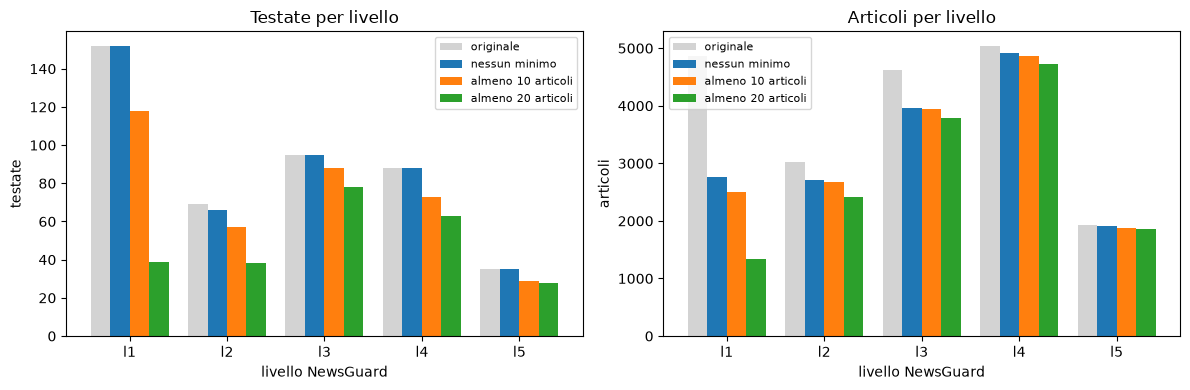

In [13]:
fig, assi = plt.subplots(1, 2, figsize=(12, 4))
for asse, misura in zip(assi, ["testate", "articoli"]):
    tabella = composizione.drop("totale").xs(misura, axis=1, level=1)
    tabella.plot.bar(ax=asse, rot=0, width=0.8, color=["lightgray", "tab:blue", "tab:orange", "tab:green"])
    asse.set_title(f"{misura.capitalize()} per livello")
    asse.set_xlabel("livello NewsGuard")
    asse.set_ylabel(misura)
    asse.legend(fontsize=8)
plt.tight_layout()
plt.show()

Quanto resta di ogni livello, rispetto al dataset originale:

In [14]:
quota = pd.DataFrame({nome: composizione[nome].stack() / composizione["originale"].stack() for nome in list(versioni)[1:]})
quota.unstack().map(lambda x: f"{x:.0%}")

nessun minimo          almeno 10 articoli          almeno 20 articoli  \
             testate articoli            testate articoli            testate   
label                                                                          
l1              100%      57%                78%      51%                26%   
l2               96%      90%                83%      89%                55%   
l3              100%      86%                93%      85%                82%   
l4              100%      98%                83%      97%                72%   
l5              100%      99%                83%      98%                80%   
totale           99%      84%                83%      81%                56%   

                 
       articoli  
label            
l1          28%  
l2          80%  
l3          82%  
l4          94%  
l5          97%  
totale      73%

## Salvataggio

- `Dataset/DatasetPulito/dataset_min0.csv`, `dataset_min10.csv`, `dataset_min20.csv`: le tre versioni
  (`article_id`, testata, gruppo, livello, testo pulito);
- `Results/1-data-cleaning/02_articoli_tolti.csv`: quali articoli sono stati tolti e perché;
- `Results/1-data-cleaning/02_composizione_versioni.csv`: la tabella qui sopra.

In [15]:
for nome, file in [("nessun minimo", "min0"), ("almeno 10 articoli", "min10"), ("almeno 20 articoli", "min20")]:
    v = versioni[nome][["article_id", "domain", "gruppo", "label", "testo_pulito"]].rename(columns={"testo_pulito": "testo"})
    v.to_csv(PULITO + f"dataset_{file}.csv", index=False)
    print(f"{file}: {len(v)} articoli, {v.domain.nunique()} testate")
df[df.motivo != "tenuto"][["article_id", "domain", "motivo"]].to_csv(RESULTS + "02_articoli_tolti.csv", index=False)
composizione.to_csv(RESULTS + "02_composizione_versioni.csv")

min0: 16270 articoli, 436 testate


min10: 15862 articoli, 365 testate


min20: 14141 articoli, 246 testate
